# Human Activity Recognition with a Hidden Markov Model

I recorded my own accelerometer and gyroscope data and use an HMM (written in numpy, in `hmm.py`) to infer
whether I'm standing, walking, jumping, or the phone is still. The clean CSVs come from `prepare_data.py`.

In [1]:
import glob, os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from hmm import GaussianHMM

os.makedirs("figures", exist_ok=True)
sns.set_theme(style="whitegrid", context="notebook")
STATES = ["standing", "walking", "jumping", "still"]
COLORS = dict(zip(STATES, ["#4C72B0", "#55A868", "#C44E52", "#8172B2"]))
SENSORS = ["acc_x", "acc_y", "acc_z", "gyro_x", "gyro_y", "gyro_z"]

## 1. Data and sampling rate

Recorded with Sensor Logger on my iPhone X at 100 Hz (10 ms). In `prepare_data.py` I merge the accelerometer and
gyroscope on their timestamp, cut 0.5 s off each end, and interpolate onto an exact 100 Hz grid. A phone recording
at another rate would go onto the same grid.

In [2]:
FS = 100
train_files = {a: sorted(glob.glob(f"data/train/{a}/*.csv")) for a in STATES}
test_files = sorted(glob.glob("data/test/*.csv"))

summary = []
for a, files in train_files.items():
    lens = [len(pd.read_csv(f)) / FS for f in files]
    summary.append(dict(activity=a, files=len(files), total_seconds=round(sum(lens), 1),
                        mean_clip_s=round(np.mean(lens), 2)))
summary = pd.DataFrame(summary)
print("Training set (100 Hz, iPhone X):")
display(summary)
print("Total training files:", summary.files.sum(), "| total test files:", len(test_files))

# check the rate after resampling
df0 = pd.read_csv(train_files["walking"][0])
dt = np.diff(df0.timestamp.values) / 1e9
print(f"Effective sampling rate after harmonisation: {1/dt.mean():.2f} Hz")

Training set (100 Hz, iPhone X):


,activity,files,total_seconds,mean_clip_s
0,standing,14,136.9,9.78
1,walking,14,115.9,8.28
2,jumping,14,116.7,8.34
3,still,14,116.3,8.31


Total training files: 56 | total test files: 4
Effective sampling rate after harmonisation: 100.00 Hz


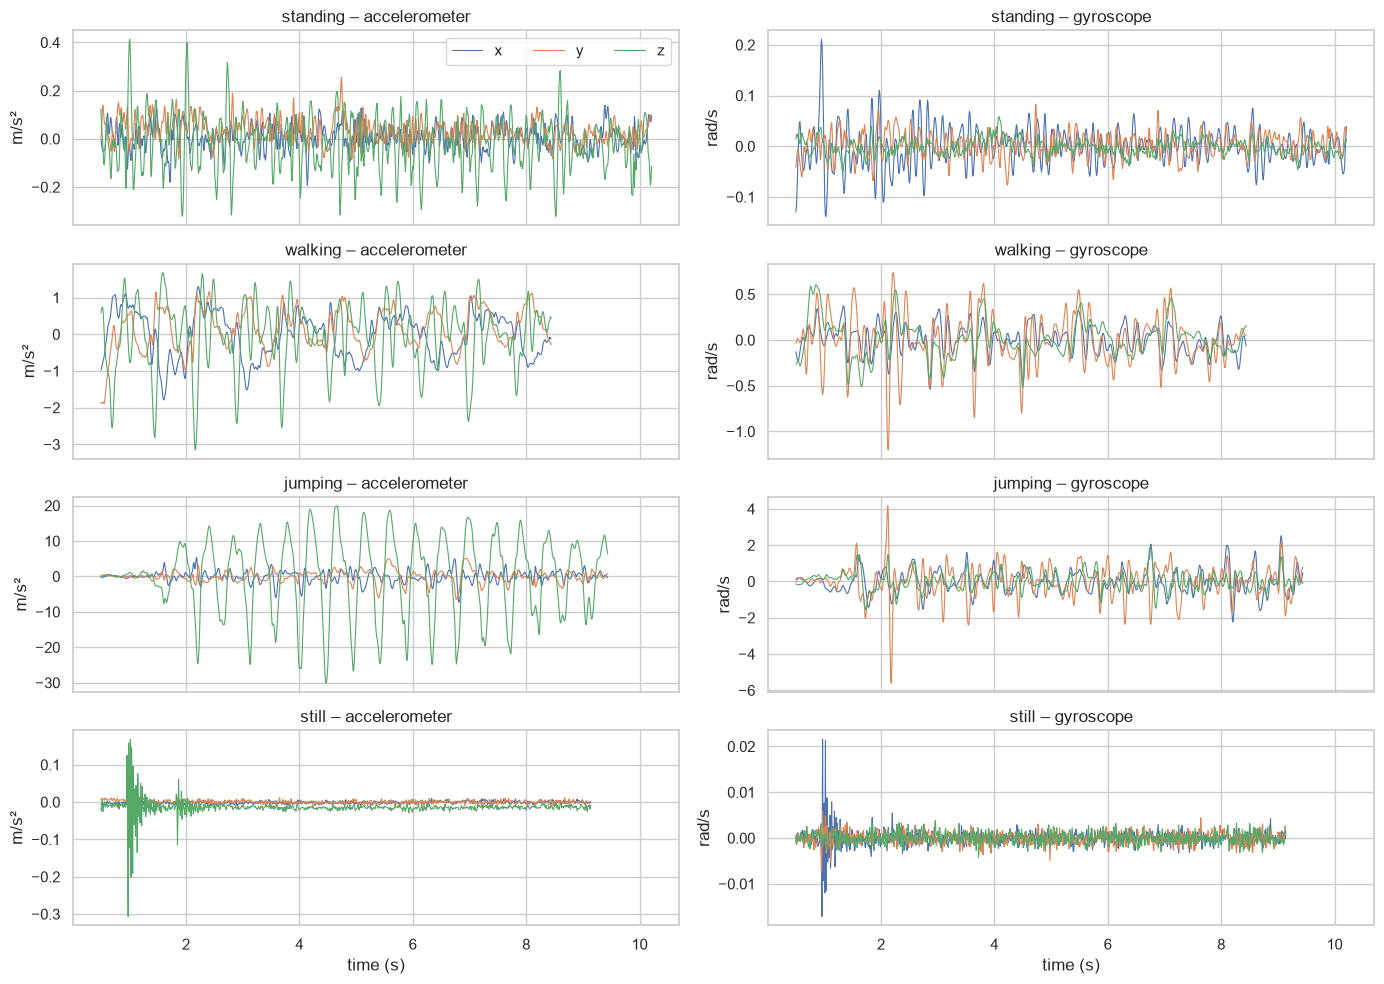

In [3]:
fig, axes = plt.subplots(4, 2, figsize=(14, 10), sharex=True)
for i, a in enumerate(STATES):
    df = pd.read_csv(train_files[a][0])
    for j, (kind, unit) in enumerate([("acc", "m/s²"), ("gyro", "rad/s")]):
        ax = axes[i, j]
        for ax_name in "xyz":
            ax.plot(df.seconds_elapsed, df[f"{kind}_{ax_name}"], lw=0.8, label=ax_name)
        ax.set_title(f"{a} – {'accelerometer' if kind == 'acc' else 'gyroscope'}")
        ax.set_ylabel(unit)
axes[0, 0].legend(ncol=3); axes[-1, 0].set_xlabel("time (s)"); axes[-1, 1].set_xlabel("time (s)")
plt.tight_layout(); plt.savefig("figures/fig1_raw_signals.png", dpi=150); plt.show()

## 2. Windowing

2 s windows (200 samples) with a 1 s hop. Walking and jumping are around 2 Hz, so a window holds 3-4 cycles, and
the FFT resolution is 100/200 = 0.5 Hz. A ~9 s clip still gives about 7 windows.

## 3. Features

All on the magnitude of acceleration and rotation, so phone orientation doesn't matter.

| Feature | Domain | Why |
|---|---|---|
| `acc_mean`, `acc_rms`, `acc_sma` | time | movement intensity: still < standing < walking < jumping |
| `acc_std` | time | jumping has big spikes, standing only small sway |
| `gyro_mean`, `gyro_std` | time | walking rotates the hip, still has no rotation |
| `acc_corr_xz` | time | axes move together during a step |
| `acc_dom_freq`, `gyro_dom_freq` | FFT | step/jump rate |
| `acc_spec_energy` | FFT | total power without the DC part |

Intensity values go from ~0.003 (still) to ~10 m/s² (jumping), so I take log10 of them to make each state look
more Gaussian.

In [4]:
WIN, HOP = 2 * FS, 1 * FS

def log_(v):
    return np.log10(v + 1e-3)

def extract_features(w):
    acc, gyr = w[SENSORS[:3]].values, w[SENSORS[3:]].values
    am, gm = np.linalg.norm(acc, axis=1), np.linalg.norm(gyr, axis=1)
    freqs = np.fft.rfftfreq(len(am), 1 / FS)
    spec = np.abs(np.fft.rfft(am - am.mean())) ** 2
    gspec = np.abs(np.fft.rfft(gm - gm.mean())) ** 2
    corr = np.corrcoef(acc[:, 0], acc[:, 2])[0, 1]
    return {
        "acc_mean": log_(am.mean()),
        "acc_std": log_(am.std()),
        "acc_rms": log_(np.sqrt((acc ** 2).mean())),
        "acc_sma": log_(np.abs(acc).sum(axis=1).mean()),
        "gyro_mean": log_(gm.mean()),
        "gyro_std": log_(gm.std()),
        "acc_corr_xz": 0.0 if np.isnan(corr) else corr,
        "acc_dom_freq": freqs[1:][spec[1:].argmax()],          # skip DC bin
        "acc_spec_energy": log_(spec[1:].sum() / len(am)),
        "gyro_dom_freq": freqs[1:][gspec[1:].argmax()],
    }

def to_windows(df):
    rows = []
    for s in range(0, len(df) - WIN + 1, HOP):
        w = df.iloc[s:s + WIN]
        f = extract_features(w)
        f["label"] = w.label.mode()[0]     # majority label inside the window
        f["t_center"] = w.seconds_elapsed.iloc[WIN // 2]
        rows.append(f)
    return pd.DataFrame(rows)

train_clips = [to_windows(pd.read_csv(f)) for a in STATES for f in train_files[a]]
test_windows = {os.path.basename(f).replace(".csv", ""): to_windows(pd.read_csv(f)) for f in test_files}
FEATURES = [c for c in train_clips[0].columns if c not in ("label", "t_center")]
train_all = pd.concat(train_clips, ignore_index=True)
print("training windows per state:"); print(train_all.label.value_counts())

training windows per state:
label
standing    114
still        96
jumping      95
walking      94
Name: count, dtype: int64


### Normalisation

Z-score, using the mean and std of the training windows only (also applied to the test set). I picked it over
min-max because jumping spikes would squash everything else, and it fits Gaussian emissions.

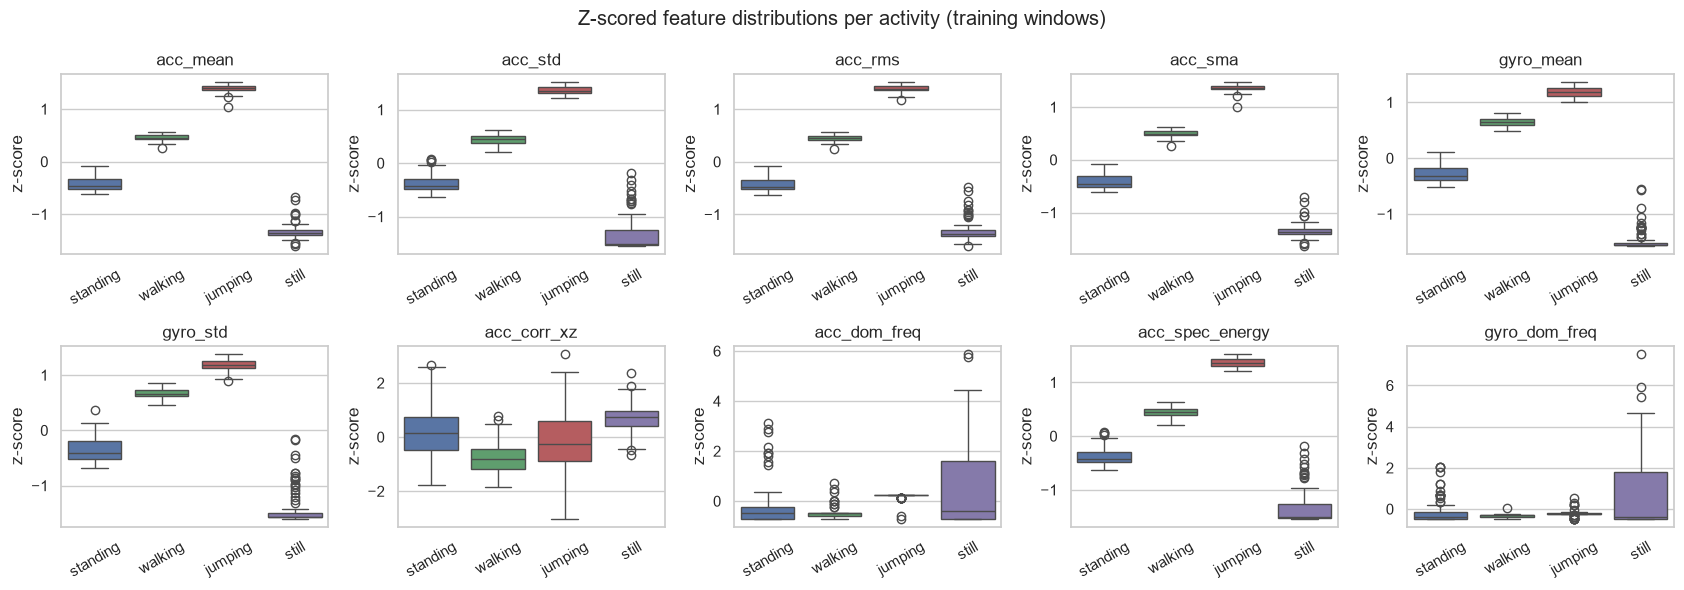

In [5]:
mu, sigma = train_all[FEATURES].mean(), train_all[FEATURES].std()
def normalise(df):
    return ((df[FEATURES] - mu) / sigma).values

fig, axes = plt.subplots(2, 5, figsize=(17, 6))
z = pd.DataFrame(normalise(train_all), columns=FEATURES); z["label"] = train_all.label
for ax, f in zip(axes.ravel(), FEATURES):
    sns.boxplot(data=z, x="label", y=f, order=STATES, hue="label", palette=COLORS, ax=ax, legend=False)
    ax.set_xlabel(""); ax.set_title(f); ax.set_ylabel("z-score"); ax.tick_params(axis="x", rotation=30)
plt.suptitle("Z-scored feature distributions per activity (training windows)")
plt.tight_layout(); plt.savefig("figures/fig2_features.png", dpi=150); plt.show()

## 4. HMM setup

| Element | Definition |
|---|---|
| States Z | standing, walking, jumping, still |
| Observations X | 10 normalised features per 2 s window |
| A | 4x4 transition matrix, one step = 1 s |
| B | diagonal Gaussian per state |
| π | starting probabilities |

**Viterbi** gives the most likely sequence of activities, which is what I score with accuracy, sensitivity and
specificity. It also smooths out one-window mistakes. **Baum-Welch** re-estimates A, B and π from the data. I start
it from the labelled estimates so the states keep their meaning, and stop when the log-likelihood changes by less
than 1e-4.

Each clip has only one activity, so I chained the clips in random order into 6 sequences to get transitions to
learn from.

In [6]:
rng = np.random.default_rng(42)
order = rng.permutation(len(train_clips))
train_seqs = [pd.concat([train_clips[i] for i in chunk], ignore_index=True)
              for chunk in np.array_split(order, 6)]
X_train = [normalise(s) for s in train_seqs]
Z_train = [s.label.map(STATES.index).values for s in train_seqs]

# 1) supervised initialisation
hmm_init = GaussianHMM(n_states=4, n_features=len(FEATURES)).init_supervised(X_train, Z_train)

# 2) Baum-Welch refinement, starting from the supervised estimates
hmm = GaussianHMM(n_states=4, n_features=len(FEATURES)).init_supervised(X_train, Z_train)
hmm.fit(X_train, tol=1e-4, max_iter=200, verbose=True)
print("converged:", hmm.converged_, "after", len(hmm.history), "iterations")

iter   0  avg log-likelihood 3.014809
iter   1  avg log-likelihood 3.155198
iter   2  avg log-likelihood 3.224044
iter   3  avg log-likelihood 3.237270
iter   4  avg log-likelihood 3.237282
converged: True after 5 iterations


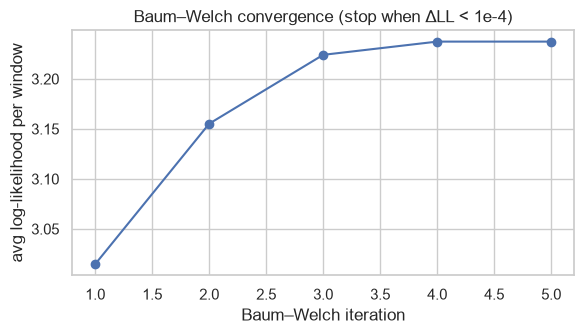

In [7]:
plt.figure(figsize=(6, 3.5))
plt.plot(range(1, len(hmm.history) + 1), hmm.history, "o-")
plt.xlabel("Baum–Welch iteration"); plt.ylabel("avg log-likelihood per window")
plt.title("Baum–Welch convergence (stop when ΔLL < 1e-4)")
plt.tight_layout(); plt.savefig("figures/fig3_convergence.png", dpi=150); plt.show()

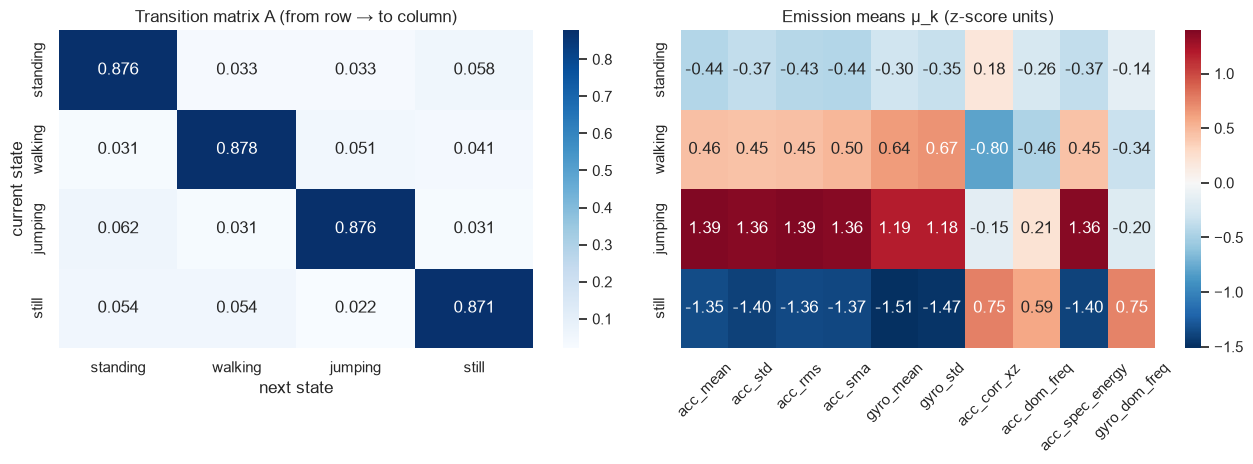

initial state probabilities π: {'standing': np.float64(0.4), 'walking': np.float64(0.1), 'jumping': np.float64(0.4), 'still': np.float64(0.1)}


In [8]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
sns.heatmap(hmm.A, annot=True, fmt=".3f", cmap="Blues", xticklabels=STATES, yticklabels=STATES, ax=axes[0])
axes[0].set_title("Transition matrix A (from row → to column)")
axes[0].set_xlabel("next state"); axes[0].set_ylabel("current state")
sns.heatmap(pd.DataFrame(hmm.means, index=STATES, columns=FEATURES), annot=True, fmt=".2f",
            cmap="RdBu_r", center=0, ax=axes[1])
axes[1].set_title("Emission means μ_k (z-score units)")
axes[1].tick_params(axis="x", rotation=45)
plt.tight_layout(); plt.savefig("figures/fig4_transition_emission.png", dpi=150); plt.show()
print("initial state probabilities π:", dict(zip(STATES, np.round(hmm.pi, 3))))

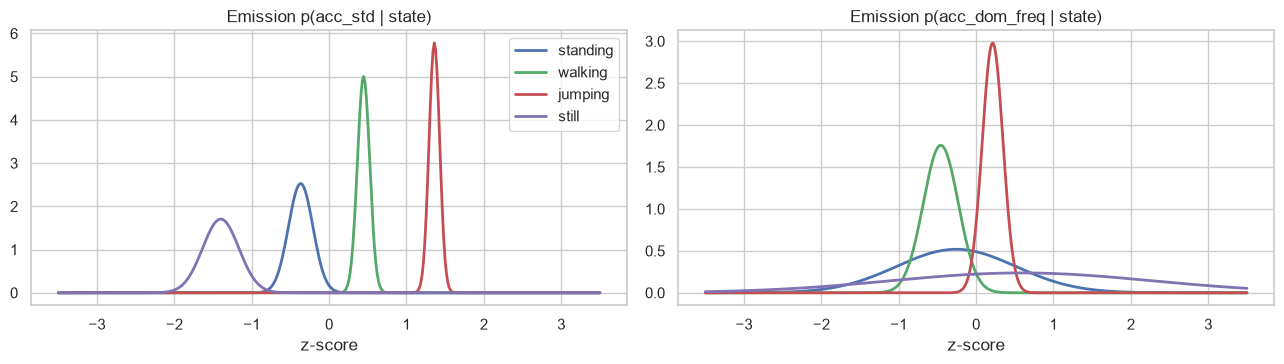

In [9]:
from scipy.stats import norm
fig, axes = plt.subplots(1, 2, figsize=(13, 3.8))
for ax, f in zip(axes, ["acc_std", "acc_dom_freq"]):
    j = FEATURES.index(f)
    xs = np.linspace(-3.5, 3.5, 400)
    for k, s in enumerate(STATES):
        ax.plot(xs, norm.pdf(xs, hmm.means[k, j], np.sqrt(hmm.vars[k, j])), color=COLORS[s], label=s, lw=2)
    ax.set_title(f"Emission p({f} | state)"); ax.set_xlabel("z-score")
axes[0].legend()
plt.tight_layout(); plt.savefig("figures/fig5_emission_densities.png", dpi=150); plt.show()

## 5. Testing on unseen data

None of these were used for training or normalisation:

* `test_session_1/2/3_continuous`: three ~40 s recordings made after the training session, doing standing → walking
  → jumping → still in one go. Labels come from the activity boundaries in the recordings.
* `test_standing_different_day`: standing, recorded on 23 Oct, three days earlier.

In [10]:
def evaluate(model):
    y_true, y_pred, decoded = [], [], {}
    for name, w in test_windows.items():
        path, _ = model.viterbi(normalise(w))
        decoded[name] = path
        y_true.extend(w.label.map(STATES.index)); y_pred.extend(path)
    return np.array(y_true), np.array(y_pred), decoded

def metrics_table(y_true, y_pred):
    rows, acc = [], (y_true == y_pred).mean()
    for k, s in enumerate(STATES):
        tp = np.sum((y_pred == k) & (y_true == k)); fn = np.sum((y_pred != k) & (y_true == k))
        tn = np.sum((y_pred != k) & (y_true != k)); fp = np.sum((y_pred == k) & (y_true != k))
        rows.append({"State (Activity)": s, "Number of Samples": int(tp + fn),
                     "Sensitivity": round(tp / (tp + fn), 3), "Specificity": round(tn / (tn + fp), 3),
                     "Overall Accuracy": round(acc, 3)})
    return pd.DataFrame(rows)

y_true, y_pred, decoded = evaluate(hmm)
y_true0, y_pred0, _ = evaluate(hmm_init)
print(f"Baum–Welch model accuracy:        {(y_true == y_pred).mean():.3f}")
print(f"Supervised-init model accuracy:   {(y_true0 == y_pred0).mean():.3f}")
for name, w in test_windows.items():
    print(f"  {name:32s} BW acc = {(decoded[name] == w.label.map(STATES.index).values).mean():.3f}")
results = metrics_table(y_true, y_pred)
results.to_csv("figures/metrics_table.csv", index=False)
results

Baum–Welch model accuracy:        0.880
Supervised-init model accuracy:   0.912
  test_session_1_continuous        BW acc = 0.892
  test_session_2_continuous        BW acc = 0.857
  test_session_3_continuous        BW acc = 0.872
  test_standing_different_day      BW acc = 1.000


,State (Activity),Number of Samples,Sensitivity,Specificity,Overall Accuracy
0,standing,35,0.914,0.922,0.88
1,walking,29,0.966,0.927,0.88
2,jumping,39,0.821,0.988,0.88
3,still,22,0.818,1.000,0.88


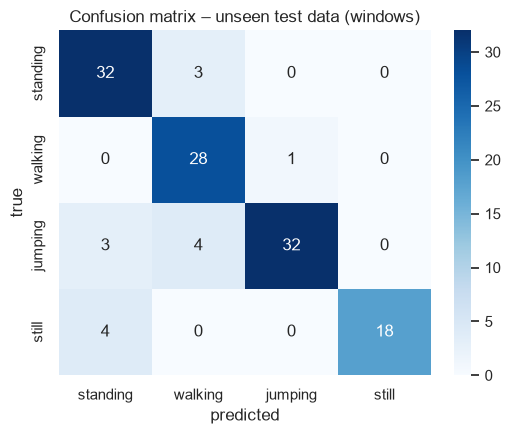

In [11]:
cm = np.zeros((4, 4), dtype=int)
np.add.at(cm, (y_true, y_pred), 1)
plt.figure(figsize=(5.5, 4.5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=STATES, yticklabels=STATES)
plt.xlabel("predicted"); plt.ylabel("true"); plt.title("Confusion matrix – unseen test data (windows)")
plt.tight_layout(); plt.savefig("figures/fig6_confusion_matrix.png", dpi=150); plt.show()

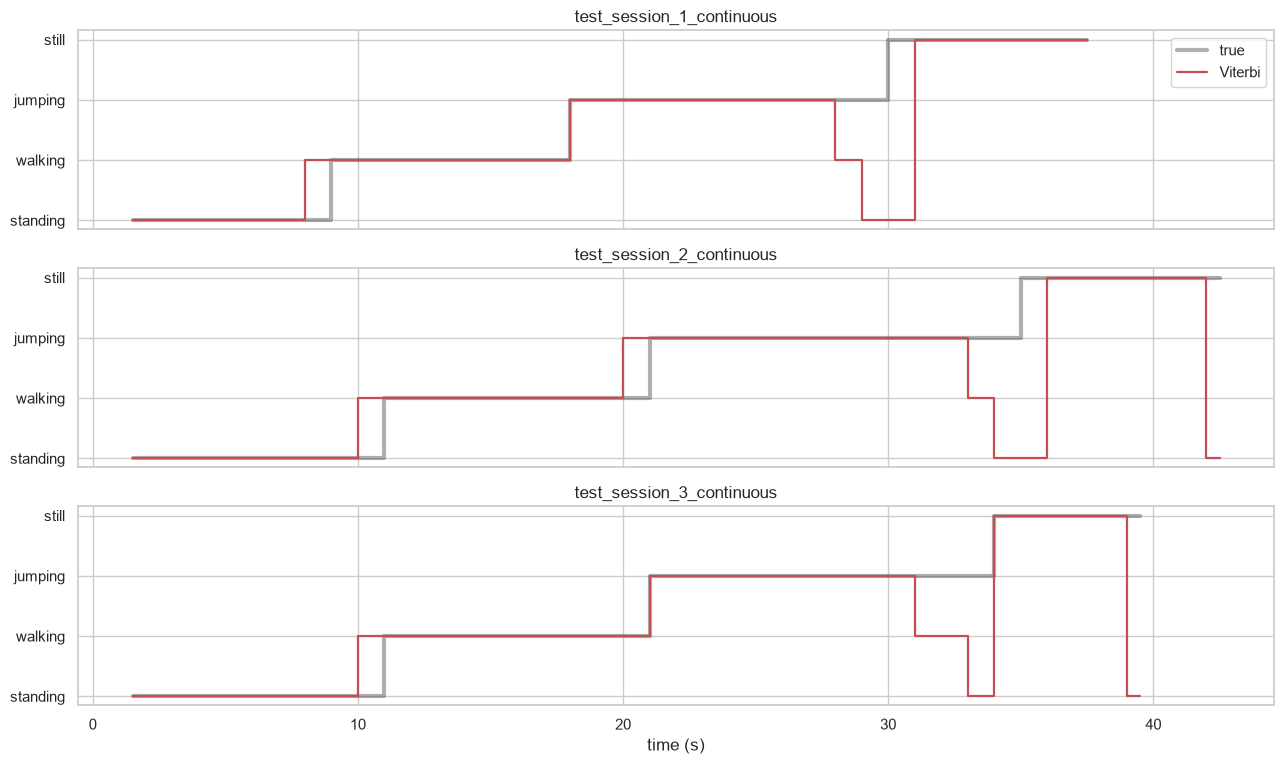

In [12]:
names = [n for n in test_windows if "continuous" in n]
fig, axes = plt.subplots(len(names), 1, figsize=(13, 2.6 * len(names)), sharex=True)
for ax, n in zip(axes, names):
    w = test_windows[n]
    ax.step(w.t_center, w.label.map(STATES.index), where="mid", color="k", lw=3, alpha=0.35, label="true")
    ax.step(w.t_center, decoded[n], where="mid", color="#C44E52", lw=1.6, label="Viterbi")
    ax.set_yticks(range(4)); ax.set_yticklabels(STATES); ax.set_title(n)
axes[0].legend(loc="upper right"); axes[-1].set_xlabel("time (s)")
plt.tight_layout(); plt.savefig("figures/fig7_decoded_sequences.png", dpi=150); plt.show()

## 6. Observations

* Still is the easiest: it is the only state with almost no signal.
* Most mistakes are at the end of jumping. The model goes jumping → walking → standing → still, which is
  actually what I did (slowing down and walking to put the phone on the table). My labels count all of that as
  jumping.
* Still windows predicted as standing are me putting the phone down or picking it up.
* Baum-Welch gives a higher likelihood but slightly lower accuracy than the labelled estimates: it is optimising
  likelihood, not accuracy, and widens the variances to cover boundary windows.